# Hypothesis 2: bus assignment and tutoring attendance

If referred students are bus riders, they will attend a smaller proportion of scheduled tutoring sessions than non-bus riders within the same school and with similar referral timing.

Run from the project folder, using the existing kernel and WireGuard/campus network. No packages are installed automatically. Required packages: numpy, pandas, matplotlib, scikit-learn, mlflow, joblib. Run cells in order. The login prompts for fresh credentials without saving them. Every fit is tracked remotely; there is no local fallback.

**Held comparable:** school, subject, referral timing, population, preprocessing, splits and estimator settings. **Varied:** addition of bus status. Mean baseline predicts the training average. Model A is ordinary linear regression on school, subject and referral timing; B adds bus status. This single-feature comparison and constant benchmark provide justified candidates. Linear regression yields an interpretable adjusted attendance difference; its common additive bus association and linear referral timing are assumptions. Predictions are not clipped; outside-[0,1] rates are reported.

Select by lowest mean three-fold validation MAE; ties prefer mean, A, B. Report RMSE, R-squared, fold spread, training scores and train-validation gaps. Preprocessing fits within each training fold. These splits evaluate new students in the same district/year, not new schools or future years. All subject rows of a student stay together.

Model B is prespecified for the hypothesis irrespective of prediction selection. Its bus coefficient is the adjusted bus-minus-non-bus difference in percentage points. Use one development Model B fit with student-clustered CR1 standard errors and a 95% t interval (G-1 degrees of freedom). An interval below zero supports the prediction, above zero rejects it, and spanning zero is unresolved. This replaces the original bootstrap plan due to repeated server interruptions; shared school/tutor shocks remain unaccounted for. Report overall and school/referral-month/subject comparisons, flagging strata without both groups.

Only the selected candidate is fit on all development data and scored once on the final test. A persistent marker prevents rescoring. H1 test results have already been inspected, so H2 is a follow-on outcome analysis rather than a wholly untouched project-wide holdout. Better prediction does not prove the predicted direction. Bus assignment is not actual transport availability; motivation, family resources and other confounding remain. Results establish association, not causation.


In [2]:
from pathlib import Path
import os, json, hashlib, platform, tempfile, getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import sklearn, mlflow, joblib
ROOT=Path.cwd()
OUT=ROOT/'hypothesis2_outputs'
SEED,BOOTSTRAPS=4913,200
CUTOFF='2026-02-18'
assert (ROOT/'cleaned').is_dir(), 'Run from project folder.'


## Read-only preparation and reuse of H1 partitions

In [3]:
def read(name):
    return pd.read_csv(ROOT/'cleaned'/f'{name}.csv',dtype={'student_id':str,'school_code':str})
h1_config=json.loads((ROOT/'hypothesis1_outputs'/'config.json').read_text())
for name,digest in h1_config['input_sha256'].items():
    assert hashlib.sha256((ROOT/'cleaned'/name).read_bytes()).hexdigest()==digest, f'Changed input: {name}'
assert h1_config['cutoff']==CUTOFF
students,refs,sessions=[read(n) for n in ['students','tutoring_referrals','tutoring_sessions']]
keys=['student_id','subject_area']
pre=sessions.loc[sessions.session_date.lt(CUTOFF)].copy()
pre['present']=pre.attendance.eq('Present').astype(int)
pre['unknown']=~pre.attendance.isin(['Present','Absent'])
a=pre.groupby(keys).agg(scheduled=('session_id','size'),attended=('present','sum'),unknown_attendance=('unknown','sum')).reset_index()
a['attendance_proportion']=a.attended/a.scheduled
cohort=refs.merge(a,on=keys,how='inner',validate='one_to_one').merge(students[['student_id','bus_rider']],on='student_id',validate='many_to_one')
cohort['bus']=cohort.bus_rider.map({'Y':1,'N':0})
cohort['referral_days']=(pd.to_datetime(cohort.referral_date)-pd.Timestamp('2025-08-01')).dt.days
cohort['referral_month']=cohort.referral_date.str[:7]
manifest_path=ROOT/'hypothesis1_outputs'/'split_manifest.csv'
manifest=pd.read_csv(manifest_path,dtype={'student_id':str})
joined=cohort.merge(manifest,on=keys,how='outer',validate='one_to_one',indicator=True)
assert joined['_merge'].eq('both').all(), 'Eligible records differ from H1: investigate before fitting.'
data=joined.drop(columns='_merge')
audit=pd.DataFrame({'measure':['all referrals','eligible student-subjects','unique students','unknown attendance records','unknown bus records'],
 'count':[len(refs),len(data),data.student_id.nunique(),data.unknown_attendance.gt(0).sum(),data.bus.isna().sum()]})
display(audit)
assert data.unknown_attendance.eq(0).all() and data.bus.notna().all(), 'Specify missing-data sensitivity before fitting.'
assert data.scheduled.gt(0).all() and data.referral_date.lt(CUTOFF).all()
assert data.attendance_proportion.between(0,1).all()
assert data.groupby('student_id').partition.nunique().eq(1).all()
dev=data.loc[data.partition.eq('development')].reset_index(drop=True)
test=data.loc[data.partition.eq('test')].reset_index(drop=True)
assert set(dev.student_id).isdisjoint(test.student_id)
assert dev.groupby('student_id').validation_fold.nunique().eq(1).all()
folds=[]
for f in sorted(dev.validation_fold.unique()):
    tr=np.flatnonzero(dev.validation_fold.ne(f)); va=np.flatnonzero(dev.validation_fold.eq(f))
    assert set(dev.iloc[tr].student_id).isdisjoint(dev.iloc[va].student_id)
    assert dev.iloc[tr].bus.nunique()==2
    folds.append((int(f),tr,va))
assert len(folds)==3
print('Exact H1 partitions/folds reused; no student overlap.')


,measure,count
0,all referrals,14917
1,eligible student-subjects,13538
2,unique students,10483
3,unknown attendance records,0
4,unknown bus records,0


Exact H1 partitions/folds reused; no student overlap.


## Course MLflow login
Run again to replace credentials. The authentication and artifact transfer checks must succeed before any fit. Keep WireGuard active. The password is not saved. Artifact storage must be accessible from this host, as checked below.

In [1]:
# This connection cell can run independently of the earlier imports cell.
import os
import getpass
import tempfile
from pathlib import Path
try:
    import mlflow
except ImportError as exc:
    raise ImportError('MLflow is not installed in this notebook kernel. Run %pip install mlflow in a separate cell, then retry.') from exc
ROOT = Path.cwd()

H2_CONNECTED = False
MLFLOW_SERVER = 'http://10.0.100.20:5000'
# Prompt on every run so previously mistyped credentials can be replaced.
username = input('Course MLflow username: ').strip()
password = getpass.getpass('Course MLflow password: ')
if not username or not password:
    raise ValueError('Enter both credentials, then rerun this cell.')
os.environ['MLFLOW_TRACKING_USERNAME'] = username
os.environ['MLFLOW_TRACKING_PASSWORD'] = password
del password
os.environ['MLFLOW_HTTP_REQUEST_TIMEOUT'] = '15'
os.environ['MLFLOW_HTTP_REQUEST_MAX_RETRIES'] = '1'
if os.environ.get('MLFLOW_TRACKING_TOKEN'):
    raise RuntimeError('An existing MLflow token overrides basic authentication; clear it for this course login.')
mlflow.set_tracking_uri(MLFLOW_SERVER)
client = mlflow.tracking.MlflowClient()
try:
    client.search_experiments(max_results=1)
except Exception as exc:
    raise RuntimeError('Cannot authenticate to course MLflow. Check campus access, credentials and server status.') from exc
experiment_name = input('H2 experiment name [Tutoring_Paradox_Hypothesis2]: ').strip() or 'Tutoring_Paradox_Hypothesis2'
if not experiment_name:
    raise ValueError('An experiment name is required.')
experiment = mlflow.set_experiment(experiment_name)
with tempfile.TemporaryDirectory(dir=ROOT) as tmp:
    probe = Path(tmp) / 'connection_check.txt'
    probe.write_text('Hypothesis 2 host artifact connectivity check', encoding='utf-8')
    with mlflow.start_run(run_name='H2_connection_preflight') as run:
        mlflow.set_tag('purpose', 'connection check; no model fitted')
        mlflow.log_artifact(str(probe), artifact_path='preflight')
        fetched = client.download_artifacts(run.info.run_id, 'preflight/connection_check.txt', tmp)
        assert Path(fetched).read_text(encoding='utf-8') == probe.read_text(encoding='utf-8')
print('Authenticated and artifact transfer verified. Ready for tracked experiments.')

H2_CONNECTED = True


🏃 View run H2_connection_preflight at: http://10.0.100.20:5000/#/experiments/120/runs/b9084509cc004bcca9fcbd567c5d3d34
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120
Authenticated and artifact transfer verified. Ready for tracked experiments.


## Configuration and descriptive comparison
Group means use equally weighted student-subject records; unique-student counts are separate. Negative differences mean lower attendance among bus riders. Strata lacking one bus group are flagged, not assigned zero differences.

In [4]:
def require_connection():
    if not globals().get('H2_CONNECTED',False) or mlflow.get_tracking_uri()!=MLFLOW_SERVER:
        raise RuntimeError('Complete the H2 connection cell first.')
    client.search_experiments(max_results=1)
require_connection()
OUT.mkdir(exist_ok=True)
config=dict(seed=SEED,cutoff=CUTOFF,bootstraps=BOOTSTRAPS,primary_metric='MAE',
    candidates=['mean','A','B'],estimator='ordinary linear regression; unweighted student-subjects',
    controls=['school','subject','referral_days'],input_sha256=h1_config['input_sha256'],
    split_sha256=hashlib.sha256(manifest_path.read_bytes()).hexdigest(),python=platform.python_version(),
    versions={m:__import__(m).__version__ for m in ['numpy','pandas','sklearn','mlflow']})
config_path=OUT/'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text())==config, 'Configuration changed: use a separate output directory.'
else:
    config_path.write_text(json.dumps(config,indent=2),encoding='utf-8')
audit.to_csv(OUT/'cohort_audit.csv',index=False)
data[keys+['partition','validation_fold']].to_csv(OUT/'split_manifest.csv',index=False)
group_summary=dev.groupby('bus_rider').agg(student_subjects=('student_id','size'),unique_students=('student_id','nunique'),
    mean_attendance=('attendance_proportion','mean'),median_attendance=('attendance_proportion','median'))
group_summary['mean_attendance_pct']=100*group_summary.mean_attendance
group_summary.to_csv(OUT/'development_group_summary.csv')
raw_diff=100*(group_summary.loc['Y','mean_attendance']-group_summary.loc['N','mean_attendance'])
display(group_summary)
print(f'Unadjusted bus-minus-non-bus difference: {raw_diff:.3f} percentage points')
strata=dev.groupby(['school_code','referral_month','subject_area','bus_rider']).attendance_proportion.agg(['size','mean']).unstack('bus_rider')
strata.columns=[f'{stat}_{bus}' for stat,bus in strata.columns]
strata=strata.reset_index()
strata['both_groups']=strata[['mean_Y','mean_N']].notna().all(axis=1)
strata['difference_pp']=100*(strata.mean_Y-strata.mean_N)
strata.to_csv(OUT/'development_strata_comparison.csv',index=False)
display(strata)
print('Comparable strata:',strata.both_groups.sum(),'of',len(strata))


,student_subjects,unique_students,mean_attendance,median_attendance,mean_attendance_pct
bus_rider,,,,,
N,4183,3275,0.617970,0.650000,61.796979
Y,6648,5111,0.531771,0.545455,53.177071


Unadjusted bus-minus-non-bus difference: -8.620 percentage points


,school_code,referral_month,subject_area,size_N,size_Y,mean_N,mean_Y,both_groups,difference_pp
0,417002,2025-08,English Language Arts,133.0,181.0,0.609480,0.515584,True,-9.389535
1,417002,2025-08,Mathematics,186.0,236.0,0.618171,0.514161,True,-10.401002
2,417002,2025-08,Science,127.0,175.0,0.589432,0.526866,True,-6.256641
3,417002,2025-09,English Language Arts,18.0,29.0,0.660842,0.457686,True,-20.315613
4,417002,2025-09,Mathematics,20.0,35.0,0.609034,0.558705,True,-5.032889
...,...,...,...,...,...,...,...,...,...
211,417087,2025-09,Mathematics,5.0,20.0,0.699722,0.550925,True,-14.879751
212,417087,2025-09,Science,5.0,4.0,0.634510,0.698611,True,6.410131
213,417087,2025-11,English Language Arts,13.0,25.0,0.559615,0.539485,True,-2.013054
214,417087,2025-11,Mathematics,22.0,27.0,0.674966,0.536064,True,-13.890122


Comparable strata: 208 of 216


## Candidate model comparison
Each fit, including the mean baseline, starts within a course MLflow run. Train-only preprocessing, common folds, saved pipelines and fold gaps make the comparison reproducible. No test scores are used here.

In [5]:
def make_model(candidate):
    if candidate=='mean': return DummyRegressor(strategy='mean')
    numeric=['referral_days']+(['bus'] if candidate=='B' else [])
    prep=ColumnTransformer([('numeric',StandardScaler(),numeric),
        ('category',OneHotEncoder(drop='first',handle_unknown='ignore'),['school_code','subject_area'])])
    return Pipeline([('features',prep),('regression',LinearRegression())])
def X(model,frame):
    return np.zeros((len(frame),1)) if isinstance(model,DummyRegressor) else frame
def fit_model(model,frame):
    return model.fit(X(model,frame),frame.attendance_proportion)
def scores(model,frame):
    y=frame.attendance_proportion; p=model.predict(X(model,frame))
    return dict(mae=float(mean_absolute_error(y,p)),rmse=float(np.sqrt(mean_squared_error(y,p))),r2=float(r2_score(y,p)),
        outside_unit_fraction=float(((p<0)|(p>1)).mean()))
def log_setup(candidate,phase,**extra):
    mlflow.set_tags({'hypothesis':'2','experiment_type':'observational association'})
    mlflow.log_params(dict(candidate=candidate,phase=phase,seed=SEED,cutoff=CUTOFF,selection_metric='MAE',
        controls='school,subject,referral_days',bus_predictor=candidate=='B',**extra))
    for path in [config_path,OUT/'split_manifest.csv',OUT/'cohort_audit.csv',ROOT/'hypothesis2_experiments.ipynb',ROOT/'PROJECT.md']:
        mlflow.log_artifact(str(path),'protocol')
def save_model(model,name):
    path=OUT/f'{name}.joblib'; joblib.dump(model,path)
    mlflow.log_artifact(str(path),'models')
require_connection()
if (OUT/'final_test_started.json').exists():
    raise RuntimeError('Final test already started: review existing results rather than reselecting.')
records=[]
for candidate in ['mean','A','B']:
    for fold,tr,va in folds:
        with mlflow.start_run(run_name=f'H2_{candidate}_fold_{fold}') as run:
            log_setup(candidate,'cross_validation',fold=fold,training_rows=len(tr),validation_rows=len(va))
            model=fit_model(make_model(candidate),dev.iloc[tr])
            train_scores=scores(model,dev.iloc[tr]); valid_scores=scores(model,dev.iloc[va])
            mlflow.log_metrics({f'train_{k}':v for k,v in train_scores.items()})
            mlflow.log_metrics({f'validation_{k}':v for k,v in valid_scores.items()})
            gaps={f'{k}_gap':valid_scores[k]-train_scores[k] for k in ['mae','rmse']}
            mlflow.log_metrics(gaps); save_model(model,f'{candidate}_fold_{fold}')
            records.append(dict(candidate=candidate,fold=fold,run_id=run.info.run_id,
                **{f'train_{k}':v for k,v in train_scores.items()},**valid_scores,**gaps))
cv_results=pd.DataFrame(records)
cv_results.to_csv(OUT/'validation_results.csv',index=False)
summary=cv_results.groupby('candidate',sort=False).agg(mae_mean=('mae','mean'),mae_std=('mae','std'),rmse_mean=('rmse','mean'),
    rmse_std=('rmse','std'),mae_gap_mean=('mae_gap','mean'),rmse_gap_mean=('rmse_gap','mean'))
summary.to_csv(OUT/'validation_summary.csv')
chosen=summary.mae_mean.idxmin()
(OUT/'selection.json').write_text(json.dumps(dict(candidate=chosen,criterion='minimum mean validation MAE; ties mean,A,B')),encoding='utf-8')
display(cv_results); display(summary)
print('Selected candidate:',chosen)


🏃 View run H2_mean_fold_0 at: http://10.0.100.20:5000/#/experiments/120/runs/4bb58e48add7412fbda7e71eaaba8364
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120
🏃 View run H2_mean_fold_1 at: http://10.0.100.20:5000/#/experiments/120/runs/1f52d842a1964bcd9dde89840ab89c3b
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120
🏃 View run H2_mean_fold_2 at: http://10.0.100.20:5000/#/experiments/120/runs/c06d4ed3642f4678b051dc7c4ca67971
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120
🏃 View run H2_A_fold_0 at: http://10.0.100.20:5000/#/experiments/120/runs/8647ab271e1b437b99afc3acba830d6e
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120
🏃 View run H2_A_fold_1 at: http://10.0.100.20:5000/#/experiments/120/runs/be763bfd9fba47b6bebc234f7f43781a
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120
🏃 View run H2_A_fold_2 at: http://10.0.100.20:5000/#/experiments/120/runs/137d8767236d4ca4a9a0c9dfb3afb863
🧪 View experiment at: http://

,candidate,fold,run_id,train_mae,train_rmse,train_r2,train_outside_unit_fraction,mae,rmse,r2,outside_unit_fraction,mae_gap,rmse_gap
0,mean,0,4bb58e48add7412fbda7e71eaaba8364,0.211058,0.250959,0.000000,0.0,0.211945,0.252127,-0.000051,0.0,0.000887,0.001168
1,mean,1,1f52d842a1964bcd9dde89840ab89c3b,0.211488,0.251333,0.000000,0.0,0.211106,0.251383,-0.000081,0.0,-0.000382,0.000050
2,mean,2,c06d4ed3642f4678b051dc7c4ca67971,0.211440,0.251747,0.000000,0.0,0.210961,0.250560,-0.000262,0.0,-0.000479,-0.001187
3,A,0,8647ab271e1b437b99afc3acba830d6e,0.210311,0.250137,0.006543,0.0,0.212542,0.253056,-0.007433,0.0,0.002230,0.002919
4,A,1,be763bfd9fba47b6bebc234f7f43781a,0.210605,0.250637,0.005530,0.0,0.211564,0.251919,-0.004350,0.0,0.000958,0.001282
5,A,2,137d8767236d4ca4a9a0c9dfb3afb863,0.211033,0.251381,0.002904,0.0,0.210765,0.250381,0.001169,0.0,-0.000268,-0.001001
6,B,0,9d615e3e6ec944e5b853e7ae79dcfd9e,0.206508,0.246664,0.033935,0.0,0.209629,0.249777,0.018504,0.0,0.003121,0.003113
7,B,1,9333095bed374ca58fd16b9cc228ef77,0.207205,0.246991,0.034253,0.0,0.208219,0.249007,0.018739,0.0,0.001013,0.002016
8,B,2,696450f073ea4a61aeb001117e609aa1,0.208128,0.248332,0.026946,0.0,0.206686,0.246291,0.033534,0.0,-0.001443,-0.002042


,mae_mean,mae_std,rmse_mean,rmse_std,mae_gap_mean,rmse_gap_mean
candidate,,,,,,
mean,0.211337,0.000531,0.251357,0.000784,0.000008,0.000010
A,0.211623,0.000890,0.251785,0.001343,0.000974,0.001067
B,0.208178,0.001472,0.248358,0.001831,0.000897,0.001029


Selected candidate: B


## Adjusted association and student-clustered uncertainty

**Method revision, November 11, 2026:** Replace 200 bootstrap refits with one Model B fit and a student-clustered CR1 sandwich covariance estimate. Repeated server disconnects motivated the change, not a preferred statistical outcome. Earlier bootstrap logs/checkpoints remain historical and are not mixed into this interval. Use a two-sided 95% Student t interval with G-1 degrees of freedom. The hypothesis, controls, population, predictive comparisons and final test remain unchanged.

The calculation groups residual score contributions by student, allowing correlation among that student's subject rows. It relies on many independent student clusters; dependence across students sharing schools/tutors remains unaccounted for. An interval below zero supports lower bus-rider attendance; above zero contradicts it; including zero is unresolved. A point and horizontal interval replace the bootstrap histogram. This procedure follows the [standard cluster covariance conventions](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html).

Run this cell instead of the old bootstrap cell. It retains bounded network retries and a separate checkpoint so a completed fit can be reused after an upload interruption.


🏃 View run H2_B_student_clustered_association at: http://10.0.100.20:5000/#/experiments/120/runs/4370010a91424184bb14ca8fe6411a2f
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120


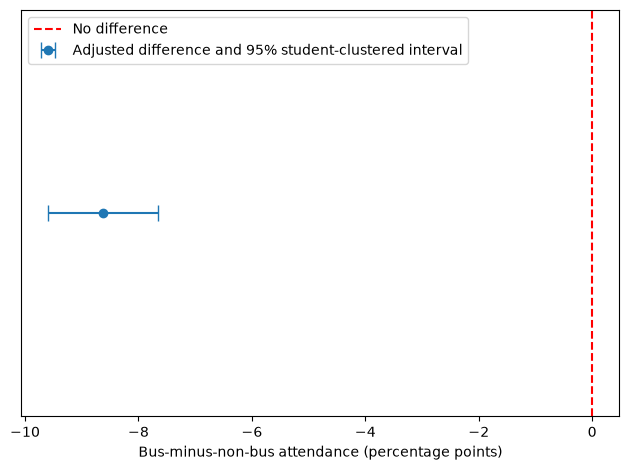

🏃 View run H2_B_student_clustered_association at: http://10.0.100.20:5000/#/experiments/120/runs/4370010a91424184bb14ca8fe6411a2f
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120
🏃 View run H2_clustered_protocol at: http://10.0.100.20:5000/#/experiments/120/runs/587d30c93b8e40c791cebb095d2af714
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120


,adjusted_bus_minus_nonbus_pp,clustered_se_pp,ci_lower_pp,ci_upper_pp,student_clusters,inference_df,observations,design_rank,uncertainty_method,verdict,unadjusted_difference_pp,run_id
0,-8.622279,0.492437,-9.587576,-7.656982,8386,8385,10831,28,student-clustered CR1; t interval with G-1 df,supported,-8.619908,4370010a91424184bb14ca8fe6411a2f


In [9]:
# One Model B fit, student-clustered CR1 covariance, and a t confidence interval.
import time
import uuid
from scipy.stats import t as student_t

def clustered_bus_interval(model, frame):
    prep=model.named_steps['features']
    transformed=prep.transform(frame)
    if hasattr(transformed,'toarray'):
        transformed=transformed.toarray()
    design=np.column_stack([np.ones(len(frame)),np.asarray(transformed,dtype=float)])
    rank=np.linalg.matrix_rank(design)
    if rank!=design.shape[1]:
        raise ValueError('Rank-deficient design: inspect collinearity before reporting inference.')
    residual=np.asarray(frame.attendance_proportion-model.predict(frame),dtype=float)
    group_codes,unique_students=pd.factorize(frame.student_id,sort=False)
    G=len(unique_students)
    N,K=design.shape
    if G<=1 or N<=K:
        raise ValueError('Insufficient independent clusters or residual degrees of freedom.')
    # Group score sums allow arbitrary residual correlation within each student.
    grouped_scores=np.zeros((G,K))
    np.add.at(grouped_scores,group_codes,design*residual[:,None])
    inverse=np.linalg.pinv(design)
    bread=inverse@inverse.T
    correction=(G/(G-1))*((N-1)/(N-K))
    covariance=correction*bread@(grouped_scores.T@grouped_scores)@bread
    names=list(prep.get_feature_names_out())
    bus_index=names.index('numeric__bus')
    scale=prep.named_transformers_['numeric'].scale_[1]
    estimate=100*model.named_steps['regression'].coef_[bus_index]/scale
    variance=float(covariance[bus_index+1,bus_index+1])
    if variance < -1e-10:
        raise ValueError('Invalid negative cluster variance.')
    se=100*np.sqrt(max(variance,0))/scale
    critical=student_t.ppf(.975,df=G-1)
    return dict(adjusted_bus_minus_nonbus_pp=float(estimate),clustered_se_pp=float(se),
        ci_lower_pp=float(estimate-critical*se),ci_upper_pp=float(estimate+critical*se),
        student_clusters=int(G),inference_df=int(G-1),observations=int(N),design_rank=int(rank),
        uncertainty_method='student-clustered CR1; t interval with G-1 df')

def retry_call(action, attempts=5):
    for attempt in range(attempts):
        try:
            return action()
        except Exception as exc:
            message=str(exc).lower()
            transient=any(word in message for word in [
                'connection aborted','remotedisconnected','connection reset','connection refused',
                'timed out','timeout','temporarily unavailable','too many requests',
                '502','503','504','429'])
            if not transient or attempt==attempts-1:
                raise
            delay=min(2**(attempt+1),16)
            print(f'Temporary MLflow interruption; retry {attempt+1}/{attempts-1} in {delay}s.')
            time.sleep(delay)

if not globals().get('H2_CONNECTED',False) or mlflow.get_tracking_uri()!=MLFLOW_SERVER:
    raise RuntimeError('Run the H2 login cell successfully first.')
retry_call(lambda: client.search_experiments(max_results=1))
if (OUT/'final_test_started.json').exists():
    raise RuntimeError('Final test started: use saved association results; do not recompute.')

checkpoint_path=OUT/'clustered_association_checkpoint.json'
config_digest=hashlib.sha256(config_path.read_bytes()).hexdigest()
if checkpoint_path.exists():
    checkpoint=json.loads(checkpoint_path.read_text(encoding='utf-8'))
    assert checkpoint['config_sha256']==config_digest, 'Checkpoint configuration differs.'
    assert checkpoint['experiment_id']==str(experiment.experiment_id), 'Reconnect to the original H2 experiment.'
    assert checkpoint['server']==MLFLOW_SERVER
else:
    checkpoint=dict(config_sha256=config_digest,experiment_id=str(experiment.experiment_id),
        server=MLFLOW_SERVER,batch_id=uuid.uuid4().hex,runs={},results={})

def save_checkpoint():
    temporary=checkpoint_path.with_suffix('.tmp')
    temporary.write_text(json.dumps(checkpoint,indent=2),encoding='utf-8')
    temporary.replace(checkpoint_path)

save_checkpoint()

def ensure_run(key, name, parent=None):
    # A create request can succeed server-side while its response is lost.
    # Search by stable recovery tags before every retry; never blindly recreate.
    if key in checkpoint['runs']:
        return checkpoint['runs'][key]
    def find_or_create():
        found=client.search_runs([str(experiment.experiment_id)],
            filter_string=f"tags.h2_batch = '{checkpoint['batch_id']}' AND tags.h2_key = '{key}'",
            max_results=100,order_by=['attributes.start_time ASC'])
        if found:
            run=found[0]
            if len(found)>1:
                print(f'Multiple matching server runs for {key}; reusing earliest run {run.info.run_id}.')
        else:
            tags={'mlflow.runName':name,'hypothesis':'2','h2_batch':checkpoint['batch_id'],
                'h2_key':key,'protocol_sha256':config_digest}
            if parent: tags['mlflow.parentRunId']=parent
            run=client.create_run(str(experiment.experiment_id),tags=tags)
        checkpoint['runs'][key]=run.info.run_id
        save_checkpoint()
        return run.info.run_id
    return retry_call(find_or_create)

def log_fit_metadata(run_id,phase,replicate=None):
    params=dict(candidate='B',phase=phase,seed=SEED,cutoff=CUTOFF,
        controls='school,subject,referral_days',bus_predictor=True,
        estimator='ordinary linear regression',unit='student-subject')
    if replicate is not None: params['replicate']=replicate
    retry_call(lambda: client.log_batch(run_id,params=[Param(k,str(v)) for k,v in params.items()]))

parent_id=ensure_run('protocol','H2_clustered_protocol')
# Shared files are uploaded once per resumable batch, not on every refit.
if not checkpoint.get('protocol_uploaded'):
    for path in [config_path,OUT/'split_manifest.csv',OUT/'cohort_audit.csv',
                 ROOT/'hypothesis2_experiments.ipynb',ROOT/'PROJECT.md']:
        retry_call(lambda path=path: client.log_artifact(parent_id,str(path),'protocol'))
    checkpoint['protocol_uploaded']=True
    save_checkpoint()


amendment={
    'date':'2026-11-11',
    'old_method':'200 whole-student bootstrap refits with percentile interval',
    'new_method':'one OLS Model B fit; student-clustered CR1 standard error; two-sided 95% t interval, G-1 df',
    'reason':'Repeated MLflow connection interruptions during bootstrap logging; reduce remote operations. Method not selected based on a preferred verdict.',
    'unchanged':'Hypothesis, population, controls, student partitions, A/B comparison, model selection and once-only final test',
    'limits':'Large-independent-student-cluster approximation; school/tutor dependence and unmeasured confounding remain.'}
(OUT/'uncertainty_method_revision.json').write_text(json.dumps(amendment,indent=2),encoding='utf-8')
retry_call(lambda: client.log_artifact(parent_id,str(OUT/'uncertainty_method_revision.json'),'protocol'))
association_id=ensure_run('clustered_association','H2_B_student_clustered_association',parent_id)
# Record this fit inside its MLflow run; shared protocol lives in the parent run.
params=dict(candidate='B',phase='clustered_association',seed=SEED,cutoff=CUTOFF,
    controls='school,subject,referral_days',bus_predictor=True,
    estimator='ordinary linear regression',uncertainty='student-clustered CR1; t G-1 df')
from mlflow.entities import Param
retry_call(lambda: client.log_batch(association_id,params=[Param(k,str(v)) for k,v in params.items()]))
if 'clustered_result' not in checkpoint:
    with mlflow.start_run(run_id=association_id):
        association_model=fit_model(make_model('B'),dev)
        result=clustered_bus_interval(association_model,dev)
        joblib.dump(association_model,OUT/'clustered_association_model.joblib')
        checkpoint['clustered_result']=result
        save_checkpoint()
else:
    result=checkpoint['clustered_result']
lo,hi=result['ci_lower_pp'],result['ci_upper_pp']
verdict='supported' if hi<0 else ('rejected' if lo>0 else 'unresolved')
result.update(verdict=verdict,unadjusted_difference_pp=float(raw_diff),run_id=association_id)
verdict_table=pd.DataFrame([result])
verdict_table.to_csv(OUT/'hypothesis_verdict.csv',index=False)
metrics={k:float(v) for k,v in result.items() if isinstance(v,(int,float))}
for key,value in metrics.items():
    retry_call(lambda key=key,value=value: client.log_metric(association_id,key,value))
retry_call(lambda: client.set_tag(association_id,'verdict',verdict))
plt.errorbar([result['adjusted_bus_minus_nonbus_pp']],[0],
    xerr=[[result['adjusted_bus_minus_nonbus_pp']-lo],[hi-result['adjusted_bus_minus_nonbus_pp']]],
    fmt='o',capsize=6,label='Adjusted difference and 95% student-clustered interval')
plt.axvline(0,color='red',linestyle='--',label='No difference')
plt.yticks([])
plt.xlabel('Bus-minus-non-bus attendance (percentage points)')
plt.legend(); plt.tight_layout()
plt.savefig(OUT/'bus_attendance_clustered_interval.png'); plt.show()
for path in [OUT/'hypothesis_verdict.csv',OUT/'clustered_association_model.joblib',
    OUT/'bus_attendance_clustered_interval.png',OUT/'development_group_summary.csv',
    OUT/'development_strata_comparison.csv',OUT/'validation_summary.csv']:
    retry_call(lambda path=path: client.log_artifact(association_id,str(path),'results'))
retry_call(lambda: client.set_terminated(association_id,status='FINISHED'))
retry_call(lambda: client.set_terminated(parent_id,status='FINISHED'))
display(verdict_table)


## Once-only final test
Run after model selection and association. The marker is created before inspecting test outcomes; interruption requires reviewing the recorded run, not deleting the marker and rescoring. Only the selected candidate is evaluated. MAE of 0.05 means average absolute error of five attendance percentage points.

In [10]:
require_connection()
marker=OUT/'final_test_started.json'
if marker.exists(): raise RuntimeError('Final test already started/scored; inspect saved results, do not rescore.')
assert (OUT/'hypothesis_verdict.csv').exists(), 'Complete the association cell first.'
chosen=json.loads((OUT/'selection.json').read_text())['candidate']
with mlflow.start_run(run_name=f'H2_{chosen}_final_test') as run:
    log_setup(chosen,'final_test',development_rows=len(dev),test_rows=len(test))
    final_model=fit_model(make_model(chosen),dev)
    save_model(final_model,'final_model')
    with marker.open('x',encoding='utf-8') as stream: json.dump(dict(run_id=run.info.run_id,candidate=chosen),stream)
    result=scores(final_model,test)
    mlflow.log_metrics({f'test_{k}':v for k,v in result.items()})
    mlflow.log_metrics({f'development_{k}':v for k,v in scores(final_model,dev).items()})
    table=pd.DataFrame([dict(candidate=chosen,run_id=run.info.run_id,**result)])
    table.to_csv(OUT/'final_test_results.csv',index=False)
    mlflow.log_artifact(str(OUT/'final_test_results.csv'),'results')
    mlflow.log_artifact(str(OUT/'validation_results.csv'),'results')
display(table)


🏃 View run H2_B_final_test at: http://10.0.100.20:5000/#/experiments/120/runs/4a6ad3b7c0f44e0291fcd4deaea9560f
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/120


,candidate,run_id,mae,rmse,r2,outside_unit_fraction
0,B,4a6ad3b7c0f44e0291fcd4deaea9560f,0.208373,0.247239,0.022344,0.0


## Export run table and numeric conclusion
This cell may be rerun without fitting or rescoring; it also exports failed runs. Save the executed notebook and commit the run table, protocol, validation tables, verdict and final test results to the course repository. MLflow uploads do not commit files or create your M2 tag. Interpret association and predictive performance separately.

In [11]:
require_connection()
runs=mlflow.search_runs(experiment_ids=[experiment.experiment_id],output_format='pandas',max_results=50000)
columns=[c for c in runs.columns if c in ['run_id','status','start_time','end_time','tags.mlflow.runName'] or c.startswith(('params.','metrics.'))]
runs[columns].to_csv(OUT/'mlflow_run_table.csv',index=False)
print('Exported',len(runs),'runs; statuses:',runs.status.value_counts().to_dict())
display(runs[columns])
if all((OUT/p).exists() for p in ['hypothesis_verdict.csv','final_test_results.csv','validation_summary.csv']):
    v=pd.read_csv(OUT/'hypothesis_verdict.csv').iloc[0]
    t=pd.read_csv(OUT/'final_test_results.csv').iloc[0]
    validation=pd.read_csv(OUT/'validation_summary.csv')
    conclusion=(f'Hypothesis 2: {v.verdict}. Adjusted development bus-minus-non-bus attendance difference: '
        f'{v.adjusted_bus_minus_nonbus_pp:.3f} percentage points (95% student-clustered interval '
        f'{v.ci_lower_pp:.3f} to {v.ci_upper_pp:.3f}; {int(v.student_clusters)} student clusters). '
        f'Controls: school, subject, referral timing. Selected {t.candidate}; once-only test MAE {t.mae:.4f} '
        f'({100*t.mae:.2f} percentage points), RMSE {t.rmse:.4f}, R-squared {t.r2:.4f}. '
        'Association does not establish causation; bus assignment is not actual transport availability. '
        'Shared school/tutor dependence and unmeasured confounding remain.')
    newline=chr(10)
    report='# Hypothesis 2 results'+newline*2+conclusion+newline*2+'Validation means, fold spread and gaps:'+newline+validation.to_csv(index=False)
    (OUT/'results_summary.md').write_text(report,encoding='utf-8')
    print(conclusion)
else:
    print('Partial runs exported. Complete remaining cells before claiming final results.')


Exported 343 runs; statuses: {'FINISHED': 342, 'RUNNING': 1}


,run_id,status,start_time,end_time,metrics.development_outside_unit_fraction,metrics.test_mae,metrics.development_rmse,metrics.test_outside_unit_fraction,metrics.development_mae,metrics.test_r2,...,params.test_rows,params.controls,params.estimator,params.uncertainty,params.replicate,params.unit,params.validation_rows,params.fold,params.training_rows,tags.mlflow.runName
0,4a6ad3b7c0f44e0291fcd4deaea9560f,FINISHED,2026-11-11 14:28:46.273+00:00,2026-11-11 14:28:50.485+00:00,0.0,0.208373,0.247503,0.0,0.207472,0.022344,...,2707,"school,subject,referral_days",NaN,NaN,NaN,NaN,NaN,NaN,NaN,H2_B_final_test
1,4370010a91424184bb14ca8fe6411a2f,FINISHED,2026-11-11 14:27:07.870+00:00,2026-11-11 14:27:18.038+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"school,subject,referral_days",ordinary linear regression,student-clustered CR1; t G-1 df,NaN,NaN,NaN,NaN,NaN,H2_B_student_clustered_association
2,587d30c93b8e40c791cebb095d2af714,FINISHED,2026-11-11 14:27:04.922+00:00,2026-11-11 14:27:19.119+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,H2_clustered_protocol
3,d30e52e3a3344024a09f5fe85401f8e3,FINISHED,2026-11-11 14:23:47.990+00:00,2026-11-11 14:23:50.301+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"school,subject,referral_days",ordinary linear regression,NaN,5,student-subject,NaN,NaN,NaN,H2_B_student_bootstrap_005
4,787bfb4219104e5b890120be4ce31f32,FINISHED,2026-11-11 14:23:43.727+00:00,2026-11-11 14:23:46.146+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"school,subject,referral_days",ordinary linear regression,NaN,4,student-subject,NaN,NaN,NaN,H2_B_student_bootstrap_004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
338,25c6f2f6f57747e9b631c32201f801ca,FINISHED,2026-11-10 21:53:31.512+00:00,2026-11-10 21:53:35.902+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"school,subject,referral_days",NaN,NaN,NaN,NaN,3611,0,7220,H2_A_fold_0
339,eb62c38c72f64ca29a6d965ca8a21707,FINISHED,2026-11-10 21:53:25.854+00:00,2026-11-10 21:53:30.404+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"school,subject,referral_days",NaN,NaN,NaN,NaN,3610,2,7221,H2_mean_fold_2
340,f5d4853c93df463b8f39dac8d4aebd8b,FINISHED,2026-11-10 21:53:19.939+00:00,2026-11-10 21:53:24.695+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"school,subject,referral_days",NaN,NaN,NaN,NaN,3610,1,7221,H2_mean_fold_1
341,a092716bedb04063a0dd860d86f0c703,FINISHED,2026-11-10 21:53:13.541+00:00,2026-11-10 21:53:18.687+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"school,subject,referral_days",NaN,NaN,NaN,NaN,3611,0,7220,H2_mean_fold_0


Hypothesis 2: supported. Adjusted development bus-minus-non-bus attendance difference: -8.622 percentage points (95% student-clustered interval -9.588 to -7.657; 8386 student clusters). Controls: school, subject, referral timing. Selected B; once-only test MAE 0.2084 (20.84 percentage points), RMSE 0.2472, R-squared 0.0223. Association does not establish causation; bus assignment is not actual transport availability. Shared school/tutor dependence and unmeasured confounding remain.
